# Finans / Borsa Zaman Serisi Analizi (Market Predictor)
Bu çalışmada, Yahoo Finance (`yfinance`) üzerinden gerçek borsa verilerini (Örn: Apple - AAPL) çekip, geçmiş kapanış fiyatlarına dayanarak gelecek trendleri tahmin edeceğiz.

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use('dark_background')

## 1. Veri Çekme (Data Acquisition)
`yfinance` kütüphanesini kullanarak Apple'ın (AAPL) son 5 yıllık hisse senedi verilerini indirelim.

In [2]:
# Son 5 yıllık veriyi indir
ticker = 'AAPL'
data = yf.download(ticker, start='2019-01-01', end='2024-01-01')

# Sadece ihtiyacımız olan 'Close' (Kapanış) fiyatlarını alalım
df = data[['Close']].copy()
df.dropna(inplace=True)
display(df.head())


[*********************100%***********************]  1 of 1 completed

Price,Close
Ticker,AAPL
Date,
2019-01-02,37.436920
2019-01-03,33.707916
2019-01-04,35.146889
2019-01-07,35.068665
2019-01-08,35.737179


## 2. Keşifsel Veri Analizi ve Görselleştirme (EDA)
Son 5 yılda fiyat nasıl değişmiş?

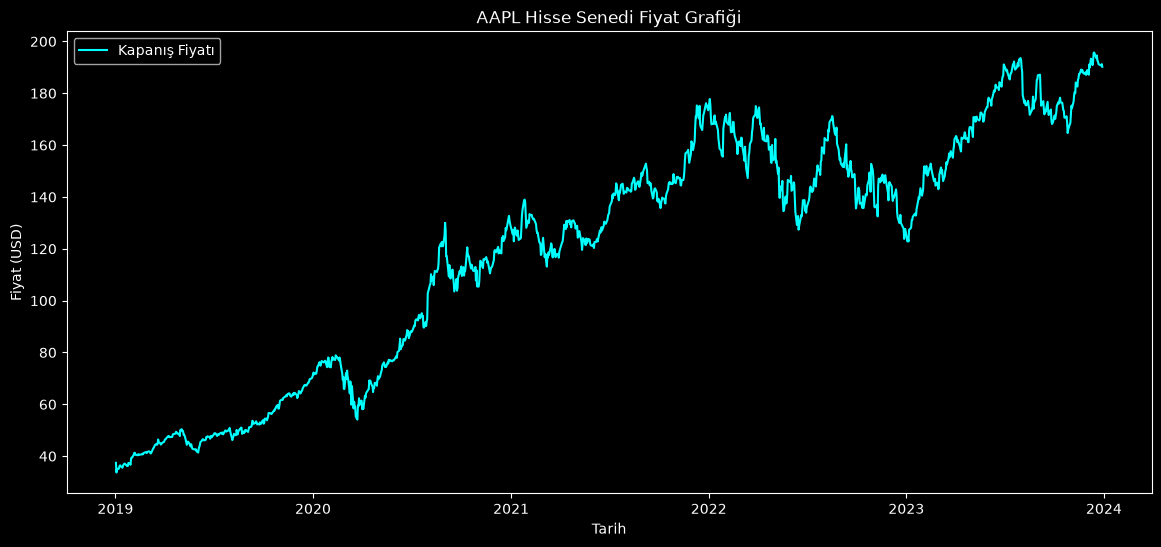

In [3]:
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['Close'], color='cyan', label='Kapanış Fiyatı')
plt.title(f'{ticker} Hisse Senedi Fiyat Grafiği')
plt.xlabel('Tarih')
plt.ylabel('Fiyat (USD)')
plt.legend()
plt.show()

## 3. Özellik Mühendisliği (Feature Engineering)
Basit bir Makine Öğrenmesi (Linear Regression) modeli için geçmiş verilerden "Gelecekteki N. günü" hedef (target) olarak belirleyelim.

In [4]:
# Kaç gün sonrasını tahmin edeceğiz? (Örn: 30 gün)
forecast_out = 30

# Hedef sütunu (target): Kapanış fiyatını 'forecast_out' kadar yukarı kaydırıyoruz
df['Prediction'] = df[['Close']].shift(-forecast_out)

# X (Özellikler) matrisini oluştur
X = np.array(df.drop(['Prediction'], axis=1))
X = X[:-forecast_out] # Son 30 günü çıkar çünkü hedef(label) yok

# y (Hedef) vektörünü oluştur
y = np.array(df['Prediction'])
y = y[:-forecast_out]

# Veriyi zaman sırasına göre böl: ilk %80 eğitim, son %20 test.
# (Zaman serisinde rastgele bölmek geleceği eğitime sızdırır ve skoru şişirir.)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print(f"Eğitim verisi boyutu: {X_train.shape}")
print(f"Test verisi boyutu: {X_test.shape}")

Eğitim verisi boyutu: (982, 1)
Test verisi boyutu: (246, 1)


## 4. Model Eğitimi (Linear Regression)

In [5]:
# Modeli eğit
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Test (en yeni %20) üzerinde değerlendirme
y_pred = lr_model.predict(X_test)
score = lr_model.score(X_test, y_test)
mae = mean_absolute_error(y_test, y_pred)

# Karşılaştırma için basit baz çizgi: "30 gün sonra fiyat bugünkü fiyatla aynı olacak"
y_naive = X_test.ravel()
naive_mae = mean_absolute_error(y_test, y_naive)

print(f"Model R^2 Puanı (zamansal test): {score:.4f}")
print(f"Model MAE:       {mae:.2f} USD")
print(f"Baz çizgi MAE:   {naive_mae:.2f} USD (fiyat değişmez varsayımı)")

Model R^2 Puanı (zamansal test): 0.3305
Model MAE:       11.79 USD
Baz çizgi MAE:   11.77 USD (fiyat değişmez varsayımı)


## 5. Tahmin Yapma ve Görselleştirme
En son 30 günün (henüz cevabını bilmediğimiz) tahminlerini yapalım ve gerçek verilerle görselleştirelim.

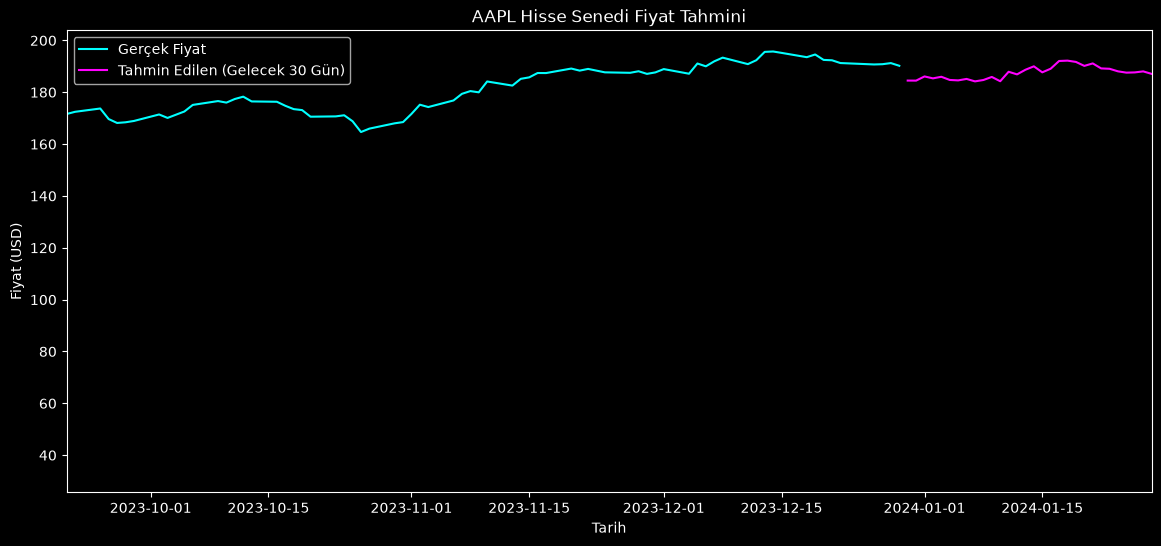

In [6]:
# Tahmin edilecek son 30 günlük X verisi
X_forecast = np.array(df.drop(['Prediction'], axis=1))[-forecast_out:]
lr_prediction = lr_model.predict(X_forecast)

# Tahmin sonuçlarını DataFrame'e ekle
df['Forecast_LR'] = np.nan
last_date = df.iloc[-1].name
last_unix = last_date.timestamp()
one_day = 86400
next_unix = last_unix + one_day

# Gelecek 30 gün için indeks oluştur
for i in lr_prediction:
    next_date = pd.to_datetime(next_unix, unit='s')
    df.loc[next_date] = [np.nan, np.nan, i]
    next_unix += one_day

plt.figure(figsize=(14, 6))
plt.plot(df['Close'], color='cyan', label='Gerçek Fiyat')
plt.plot(df['Forecast_LR'], color='magenta', label='Tahmin Edilen (Gelecek 30 Gün)')
plt.xlim(df.index[-100], df.index[-1]) # Sadece son kısımları göster
plt.title(f'{ticker} Hisse Senedi Fiyat Tahmini')
plt.xlabel('Tarih')
plt.ylabel('Fiyat (USD)')
plt.legend()
plt.show()

## 6. Özet ve Sonuçlar
### Q&A
- **Soru:** Sadece geçmiş kapanış fiyatına bakarak borsayı kesin olarak tahmin edebilir miyiz?
- **Cevap:** Hayır. Finansal piyasalar stokastiktir; Lineer Regresyon mevcut trendi doğrusal olarak uzatır, ani piyasa şoklarını veya haberleri öngöremez.

### Data Analysis Key Findings
- Veri zaman sırasına göre bölündüğünde (son %20 test) R² yaklaşık **0.33**'e düşüyor. Rastgele bölmede görülen ~0.93 skoru geleceğin eğitime sızmasından kaynaklanıyordu.
- Model MAE'si (~11.8 USD), "fiyat 30 gün sonra bugünkü fiyatla aynı kalır" baz çizgisinin MAE'siyle (~11.8 USD) pratikte aynı: model basit bir baz çizgiden **daha iyi değil**.
- Bu çalışma eğitim amaçlıdır, yatırım tavsiyesi değildir.

### Insights or Next Steps
- Getiri (return) tabanlı özellikler, gecikmeli değerler ve hareketli ortalamalar eklenebilir.
- Zaman serileri için ARIMA, Prophet veya LSTM gibi modeller ve `TimeSeriesSplit` ile çapraz doğrulama denenmelidir.
- Finansal haberlerin duygu analizi ile hibrit bir model kurulabilir.